# Inferencia Bayesiana

En el caso de estar usando Google Colab, necesitamos instalar PreliZ.

In [1]:
%%capture
# En Colab instalamos PreliZ. En un entorno que ya lo tiene no hace falta.
import importlib.util

if (
    importlib.util.find_spec("preliz") is None
    or importlib.util.find_spec("arviz_base") is None
):
    %pip install preliz
    %pip install arviz_base

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import preliz as pz

COLORES = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

g++ not available, if using conda: `conda install gxx`


# Regla de Bayes


La regla de Bayes no es más que una consecuencia directa de la regla del producto:

$$
\begin{aligned}
P(A, B) &= P(A \mid B) P(B) \\
P(A, B) &= P(B \mid A) P(A)
\end{aligned}
$$

Como ambos términos a la derecha de la igualdad son iguales, podemos escribir:

$$
P(A \mid B) P(B) = P(B \mid A) P(A)
$$

y reordenando llegamos a

$$
P(A \mid B) = \frac{P(B \mid A)P(A)}{P(B)}
$$

que es la famosa regla de Bayes.

# Modelos bayesianos

Escribir la regla de Bayes de la siguiente manera no dice mucho:

$$
P(A \mid B) = \frac{P(B \mid A)P(A)}{P(B)}
$$

Además, lo único bayesiano en ella es el nombre.

Hay dos ideas centrales que hacen que un método sea **bayesiano**:

* Toda **cantidad desconocida** es modelada utilizando una **distribución de probabilidad** de algún tipo.
* La regla de Bayes es usada para **actualizar dicha distribución a la luz de los datos**.

En el universo bayesiano, las cantidades conocidas son consideradas fijas y usualmente les llamamos datos ($y$ o $\boldsymbol{y}$).

Por el contrario, las cantidades desconocidas se consideran variables aleatorias y conforman el conjunto de parámetros ($\theta$ o $\boldsymbol{\theta}$).

Para construir un modelo bayesiano necesitamos:

* Un **modelo para las observaciones**, que nos habla de cómo se pudieron haber generado los datos $p(Y = y\mid \theta)$ (a.k.a. **verosimilitud** o **_likelihood_**).
* Un **modelo, _a priori_,** para los **parámetros** del modelo observacional $p(\theta)$ (a.k.a. **_prior_**).

La combinación de ambos da lugar a lo que se conoce como _full Bayesian model_:

$$
p(y, \theta) = p(y \mid \theta) p(\theta)
$$

que refleja **todos nuestros supuestos** sobre el fenómeno bajo estudio.

Dado un conjunto de observaciones, se obtiene una distribución _a posteriori_ para los parámetros del modelo:

$$
p(\theta \mid Y = y)
    = \frac{p(Y = y \mid \theta) p(\theta)}{p(Y = y)}
    =  \frac{\overbrace{p(Y = y\mid \theta)}^{\text{likelihood}} \overbrace{p(\theta)}^{\text{prior}}}{\underbrace{\int_{\Theta} p(Y =y \mid \theta) p(\theta) \text{d}\theta}_{\text{likelihood marginal}}}
$$

De manera más concisa, se suele escribir:

$$
p(\theta \mid y) = \frac{p(y \mid \theta) p(\theta)}{p(y)}
$$

El denominador, llamado _likelihood marginal_ o evidencia, es el _likelihood_ promediado sobre todas las posibles hipótesis $\theta$ (i.e. configuraciones posibles del modelo observacional).

El _likelihood marginal_ puede ser visto como una constante de normalización que hace que la densidad _a posteriori_ integre a 1. Por esa razón también se suele ver:

$$
p(\theta \mid Y = y) \propto p(Y = y\mid \theta)p(\theta) = p(Y = y, \theta)
$$

El trabajo de un bayesiano no termina en el hallazgo de la distribución _a posteriori_ de $\theta$ expresado como una función de densidad.

A partir de esa distribución _a posteriori_ se obtienen cantidades de interés:

* Media
* Varianza
* Percentiles
    * Mediana
    * Intervalos de credibilidad
* Probabilidades

¿Qué tienen en común estas cantidades? Todas se obtienen como valores esperados de la forma:

$$
\mathbb{E}[\varphi(\theta)] = \int \varphi(\theta) p(\theta \mid Y = y) d\theta
$$

Por ejemplo, la media o esperanza _a posteriori_ de $\theta$ es

$$
\mathbb{E}[\theta] = \int \theta p(\theta \mid Y = y) d\theta
$$

## Resumen

Un enfoque bayesiano es aquel que utiliza distribuciones de probabilidad para cuantificar la incertidumbre.

Se necesita:

1. Asumir un modelo observacional $p(Y = y \mid \theta)$.
2. Asumir un modelo para los parámetros de configuración del modelo observacional $p(\theta)$.
3. Actualizar la distribución sobre los parámetros a la luz de los datos, obteniendo $p(\theta \mid Y = y)$.
4. Extraer _insights_ de interés en forma de valores esperados obtenidos a partir del _posterior_.

## Una dosis de realidad

Dados nuestros supuestos, lo mejor que podemos hacer para actualizar nuestro conocimiento a partir de los datos es utilizar la regla de Bayes.

Sin embargo, no debemos perder de vista que la fiabilidad de los resultados que obtengamos va a depender de qué tan compatibles son nuestros supuestos iniciales con el "verdadero" proceso generador de datos. Es decir, es necesario evaluar el modelo. Algunas posibilidades son:

* Comparar las predicciones generadas por el modelo con los datos observados
* Evaluar si las conclusiones obtenidas tienen sentido dado el marco conceptual en  que se trabaja
* Determinar si los resultados obtenidos son sensibles a detalles del modelo (sobre todo aquellos detalles para los cuales no tenemos demasiada información)
* ...

Además, es posible que realizar inferencia bayesiana sea demasiado costosa en la práctica por lo que sea conveniente incorporar simplificaciones.

A fin de cuentas, el desarrollo de un modelo bayesiano es casi siempre el resultado de un proceso iterativo donde uno va logrando, paso a paso, un mayor nivel de granularidad en la descripción de un fenómeno, hasta llegar a un nivel que sea "lo suficientemente bueno".

# Aplicación

Vamos a trabajar con el problema del agua en la Tierra de manera analítica, sin utilizar PyMC. El objetivo es aplicar los componentes fundamentales del modelado bayesiano y examinar cómo cambian las respuestas al incorporar datos o modificar el _prior_.

## Agua en la Tierra

¿Qué proporción de la superficie de la Tierra está cubierta por agua?

Siguiendo el ejemplo de McElreath en *Statistical Rethinking* (capítulo 2), hacemos girar un globo, señalamos un punto y registramos si encontramos agua o tierra. Repetimos el experimento 9 veces y observamos 6 veces agua y 3 veces tierra.

A partir de los datos, ¿qué se puede concluir sobre la proporción de agua en la Tierra?

¿Qué supuesto(s) realizamos? ¿Cuál(es)?

A pensar un poco...

**¿Cuál es un modelo observacional plausible?**

La variable observada es la **cantidad de veces que observamos agua**. Es un conteo. Toma valores enteros y su mínimo valor posible es 0 (cuando no observamos agua en ningún ensayo). El máximo valor que puede tomar es la cantidad de veces que hacemos girar el globo (cuando observamos agua en todos los ensayos).

Es posible pensar que cada giro del globo es un intento o ensayo con dos resultados posibles: éxito (cuando observamos agua) y fracaso (cuando observamos tierra). Este tipo de ensayo, con dos resultados posibles, se conoce como [ensayo de Bernoulli](https://es.wikipedia.org/wiki/Ensayo_de_Bernoulli). La cantidad observada es la cantidad de éxitos obtenidos.

También se puede suponer que en cada ensayo hay una probabilidad $\theta$ de que el punto señalado esté cubierto por agua.
Si se asume que esta probabilidad de éxito es constante y que los resultados de los ensayos son todos independientes entre sí dado $\theta$, la sucesión de ensayos (cada vez que hacemos girar el globo) se conoce como [proceso de Bernoulli](https://es.wikipedia.org/wiki/Proceso_de_Bernoulli).

Bajo los supuestos mencionados, la cantidad de éxitos obtenidos en una cantidad fija de ensayos sigue una [distribución binomial](https://es.wikipedia.org/wiki/Distribuci%C3%B3n_binomial). En otras palabras, si estamos dispuestos a asumir los supuestos de los párrafos anteriores, surge naturalmente la distribución binomial como modelo observacional para describir el número de veces que observamos agua en $n$ intentos.

Escribimos

$$
Y \mid \theta \sim \text{Binomial}(n, \theta)
$$

donde:

* $Y$ cantidad de éxitos en $n$ ensayos (cantidad de veces que observamos agua en $n$ giros).
* $\theta$ probabilidad de obtener un éxito en un ensayo cualquiera (proporción de agua en la superficie de la Tierra).

Para identificar esa probabilidad con la proporción de agua, estamos suponiendo que el mecanismo de selección no favorece ninguna región de la superficie. Si siempre señalamos cerca del ecuador, por ejemplo, ¿estaríamos respondiendo la misma pregunta?

Veamos qué resultados podríamos observar para distintos valores de $\theta$.

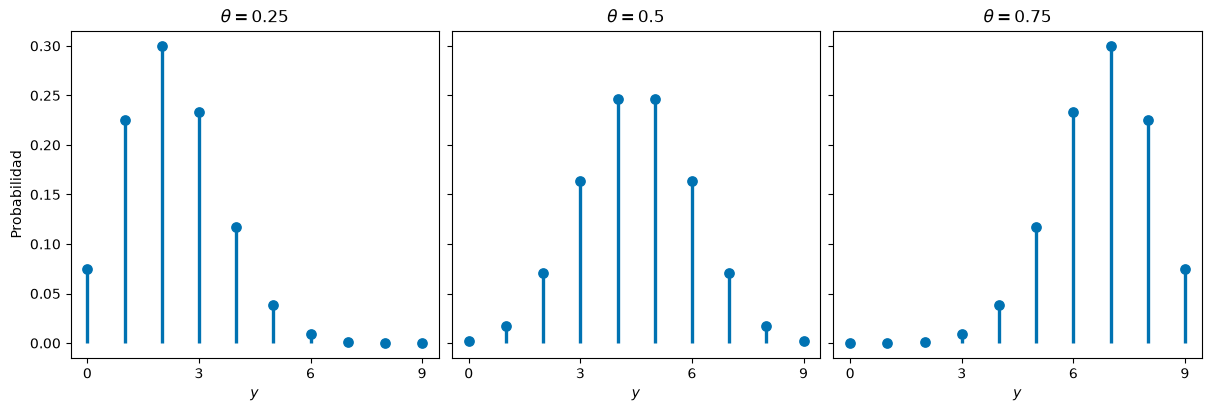

In [3]:
n_globo, y_globo = 9, 6
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")

proporciones_agua = [0.25, 0.5, 0.75]

for ax, probabilidad in zip(axes, proporciones_agua):
    valores = np.arange(n_globo + 1)
    modelo = pz.Binomial(n=n_globo, p=probabilidad)
    probabilidades = modelo.pdf(valores)
    ax.vlines(valores, 0, probabilidades, color=COLORES[0], linewidth=2.4)
    ax.scatter(valores, probabilidades, color=COLORES[0], s=45, zorder=3)
    ax.set(xlabel="$y$", title=rf"$\theta={probabilidad}$", xticks=[0, 3, 6, 9])

axes[0].set_ylabel("Probabilidad");

**¿Cuáles son las cantidades conocidas y desconocidas de este modelo?**

La distribución binomial tiene dos parámetros (o variables de configuración). La cantidad de ensayos $n$ es una cantidad fija y conocida que es igual a $n = 9$ en nuestro problema. Por otro lado, la probabilidad de éxito $\theta$ es una cantidad desconocida. De hecho, es la cantidad para la cuál queremos hacer inferencia.

Una vez observados los datos, fijamos $y=6$ y variamos $\theta$:

$$
p(Y=6\mid\theta)=\binom{9}{6}\theta^6(1-\theta)^3.
$$

Esta es la **función de verosimilitud**. Nos permite comparar valores de $\theta$ según su compatibilidad con los datos observados. ¡No es una distribución de probabilidad sobre $\theta$!

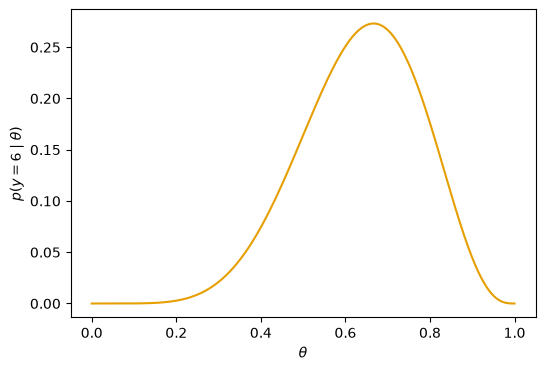

In [4]:
theta_grid = np.linspace(0.0001, 0.9999, 1000)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(theta_grid, pz.Binomial(n=n_globo, p=theta_grid).pdf(y_globo), color=COLORES[1])
ax.set(xlabel=r"$\theta$", ylabel=r"$p(y=6 \mid \theta)$");

**¿Cuál es un modelo plausible para las cantidades desconocidas?**

Hay un solo parámetro desconocido en nuestro modelo, $\theta$. Un primer paso para proponer un modelo plausible (i.e. una distribución _a priori_) para este es determinar el dominio o soporte del parámetro.

El parámetro $\theta$ es una probabilidad. Es una cantidad continua que toma valores mayores o iguales a 0 y menores o iguales a 1. Por lo tanto, tenemos que considerar a las distribuciones de probabilidad cuyo soporte es el intervalo $[0, 1]$.

Una de las familias de distribuciones con soporte en el intervalo  $[0, 1]$ más populares es la [distribución beta](https://es.wikipedia.org/wiki/Distribuci%C3%B3n_beta). Es popular por su flexibilidad para representar diferentes supuestos sobre la probabilidad de éxito y su conveniencia computacional en la estadística bayesiana.

En su parametrización más común, la distribución beta depende de dos parámetros de forma positivos $\alpha$ y $\beta$.

Veamos la forma de la función de densidad para diferentes combinaciones de los parámetros $\alpha$ y $\beta$.

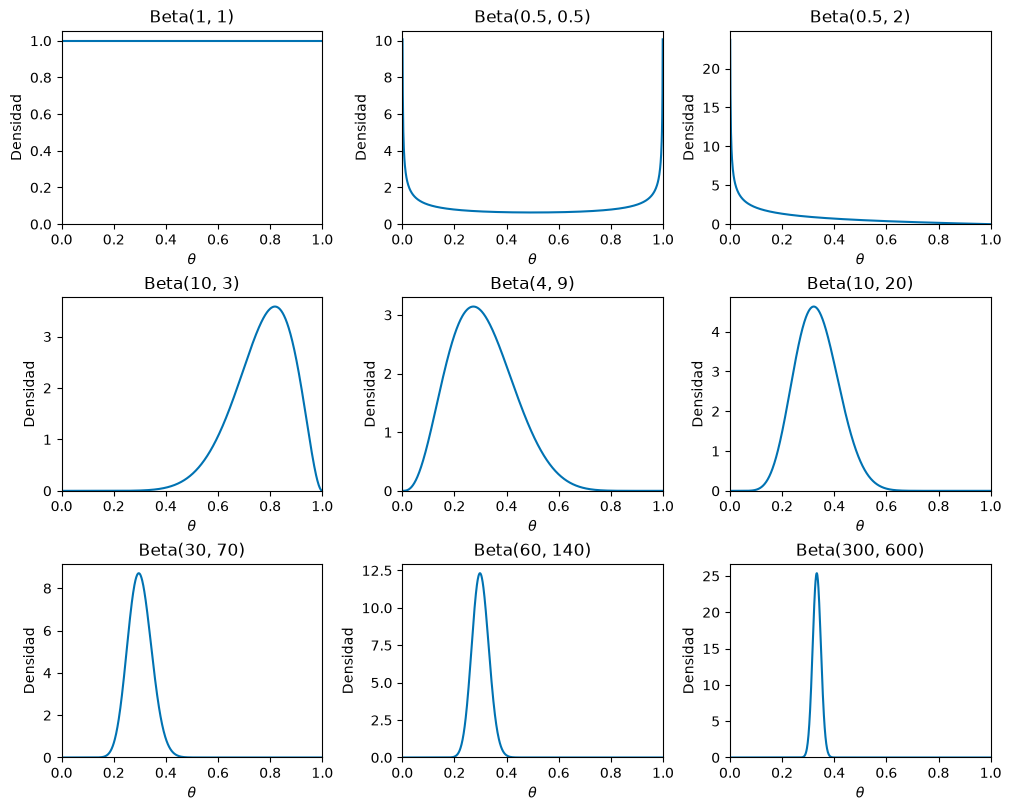

In [5]:
beta_params = [
    (1, 1),
    (0.5, 0.5),
    (0.5, 2),
    (10, 3),
    (4, 9),
    (10, 20),
    (30, 70),
    (60, 140),
    (300, 600),
]

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharey=False, layout="constrained")
beta_grid = np.linspace(0, 1, 1000)

ejes = axes.flat

for ax, (alpha, beta) in zip(ejes, beta_params):
    distribucion = pz.Beta(alpha=alpha, beta=beta)
    ax.plot(beta_grid, distribucion.pdf(beta_grid), color=COLORES[0])
    ax.set(
        title=f"Beta({alpha}, {beta})",
        xlabel=r"$\theta$",
        ylabel="Densidad",
        xlim=(0, 1),
        ylim=(0, None),
    )
    ax.tick_params(axis="y", left=True, labelleft=True)

Si bien $\alpha$ y $\beta$ son cantidades continuas, es posible interpretarlas como (pseudo-) cantidades de éxitos y fracasos. Manteniendo $\beta$ fijo, cuando $\alpha$ crece, mayor concentración de probabilidad alrededor de valores cercanos a 1. Manteniendo $\alpha$ fijo, cuando $\beta$ crece, mayor concentración de probabilidad en valores cercanos a 0.

Para este primer cálculo usamos un _prior_ uniforme en $\theta$: asignamos la misma probabilidad a intervalos de igual longitud dentro de $[0,1]$. La distribución $\text{Beta}(1,1)$ es justamente una $\text{Uniforme}(0,1)$.

No estamos usando información sobre mapas o mediciones previas de la superficie terrestre. Más adelante vamos a ver qué pasa si cambiamos este supuesto.

Luego de una larga explicación de por qué proponemos el modelo que proponemos, podemos presentarlo resumidamente de la siguiente forma:

$$
\begin{aligned}
Y \mid \theta &\sim \text{Binomial}(n, \theta) \\
\theta &\sim \text{Beta}(\alpha, \beta)
\end{aligned}
$$

Este modelo es muy popular en estadística bayesiana y se conoce como modelo beta-binomial. A partir de este modelo bayesiano y los datos observados, simplemente la cantidad de éxitos $y=6$, queremos obtener el _posterior_.

Utilizando la regla de Bayes, es posible demostrar que la densidad _a posteriori_ $p(\theta \mid Y = y)$ es también la de una distribución beta con parámetros:

$$
\begin{aligned}
\alpha_n &= y + \alpha \\
\beta_n &= n - y + \beta
\end{aligned}
$$

---

**Demostración**

El modelo Beta–Binomial se escribe:

$$
\begin{aligned}
Y \mid \theta &\sim \text{Binomial}(n, \theta) \\
\theta &\sim \text{Beta}(\alpha, \beta)
\end{aligned}
$$

y se cuenta con las siguientes funciones de masa de probabilidad y de densidad:

$$
\begin{aligned}
p(y \mid \theta) &= \binom{n}{y} \theta^y (1-\theta)^{n-y} \\
p(\theta \mid \alpha, \beta) &= \frac{1}{B(\alpha,\beta)} \theta^{\alpha - 1} (1-\theta)^{\beta - 1}
\end{aligned}
$$

donde $B(\alpha,\beta) = \dfrac{\Gamma(\alpha)\Gamma(\beta)}{\Gamma(\alpha+\beta)}$ es la función Beta.

La densidad _a posteriori_ de $\theta$ es proporcional al producto de $p(y \mid \theta)$ y $p(\theta \mid \alpha, \beta)$:

$$
\begin{aligned}
p(\theta \mid y) &\propto
    \binom{n}{y} \theta^y (1-\theta)^{n-y} \cdot
    \frac{1}{B(\alpha,\beta)} \theta^{\alpha - 1} (1-\theta)^{\beta - 1} \\
&= \displaystyle \frac{\binom{n}{y}}{B(\alpha,\beta)} \;
    \theta^{y+\alpha-1} (1-\theta)^{n-y+\beta-1}.
\end{aligned}
$$

Esto puede expresarse como:

$$
p(\theta \mid y) = K^* \; \theta^{y+\alpha-1} (1-\theta)^{n-y+\beta-1}.
$$

Por condición de cierre de una función de densidad Beta:

$$
\int_0^1 K^* \; \theta^{y+\alpha-1} (1-\theta)^{n-y+\beta-1} \, d\theta = 1,
$$

se tiene que:

$$
K^* = \frac{1}{B(y+\alpha, n-y+\beta)}.
$$

Finalmente:

$$
\theta \mid y \sim \text{Beta}(\alpha_n,\beta_n),\qquad
\alpha_n=\alpha+y,\quad\beta_n=\beta+n-y.
$$

---

En nuestro caso tenemos $y = 6$ en $n = 9$ giros. Si utilizamos un _prior_ uniforme, se tiene:

$$
\begin{aligned}
Y \mid \theta &\sim \text{Binomial}(9, \theta) \\
\theta &\sim \text{Beta}(1, 1) \\
\theta \mid y &\sim \text{Beta}(\underbrace{7}_{6 + 1}, \underbrace{4}_{9 - 6 + 1})
\end{aligned}
$$

Se dice que la familia beta es **conjugada** de la binomial: el _prior_ y el _posterior_ pertenecen a la misma familia de distribuciones.

Y podemos graficar la densidad a _priori_ junto con la densidad _a posteriori_.

In [6]:
def marcar_intervalo(ax, distribucion, color):
    inferior, superior = distribucion.eti(mass=0.95, fmt="none")
    ax.plot([inferior, superior], [0, 0], color=color, linewidth=2.5, clip_on=False)
    ax.plot(distribucion.mean(), 0, "o", color=color, clip_on=False, zorder=5)


def formatear_intervalo(intervalo):
    inferior, superior = intervalo
    return f"[{inferior:.3g}, {superior:.3g}]"


def resumir(distribucion):
    inferior, superior = distribucion.eti(mass=0.95, fmt="none")
    print(f"Media: {distribucion.mean():.3g}")
    print(f"IC central del 95%: [{inferior:.3g}, {superior:.3g}]")

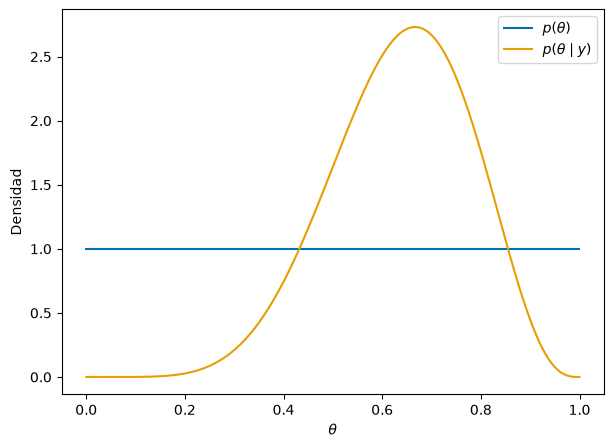

In [7]:
# Parámetros del prior
a_prior, b_prior = 1, 1

# Parámetros del posterior
a_posterior, b_posterior = 1 + y_globo, 1 + n_globo - y_globo

# Prior y posterior en preliz
theta_prior = pz.Beta(a_prior, b_prior)
theta_posterior = pz.Beta(a_posterior, b_posterior)
theta_grid = np.linspace(0.0001, 0.9999, num=200)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(theta_grid, theta_prior.pdf(theta_grid), color=COLORES[0], label="$p(\\theta)$")
ax.plot(
    theta_grid,
    theta_posterior.pdf(theta_grid),
    color=COLORES[1],
    label="$p(\\theta \\mid y)$",
)
ax.legend()
ax.set(xlabel="$\\theta$", ylabel="Densidad");

Es posible ver la "actualización" que se produjo en el conocimiento sobre $\theta$. _A priori_, pensábamos que todos los valores de $\theta$ eran igualmente probables. _A posteriori_, vemos que los valores más plausibles de $\theta$ son aquellos entre 0.3 y 0.9 (construyendo un intervalo a ojo).

Sin embargo, el gráfico que creamos por sí solo no da respuesta a nada... ¿Cómo resumimos la información en la distribución para responder a la pregunta inicial? Calculando cantidades de interés a partir de la distribución _a posteriori_ (i.e. valores esperados).

En particular, busquemos la media _a posteriori_ y un intervalo de credibilidad del 95%. Esto nos va a dar un rango donde se encuentra la mayor parte de la masa de probabilidad y por lo tanto los valores más plausibles de $\theta$.

Para obtener la media _a posteriori_ simplemente usamos el método `.mean()` de la distribución creada con PreliZ.

In [8]:
theta_posterior.mean()  # es igual a alfa / (alfa + beta)

array(0.63636364)

Y para un intervalo de credibilidad el método `.eti()` (_Equal-tailed interval_).

In [9]:
print(formatear_intervalo(theta_posterior.eti(mass=0.95, fmt="none")))

[0.348, 0.878]


Este intervalo es central, de colas iguales: deja un 2.5% de probabilidad en cada cola de la distribución.

De esta manera, podemos dar respuesta a la pregunta inicial (¿qué proporción de la superficie de la Tierra está cubierta por agua?) de dos maneras distintas:

* Si tenemos que responder con un solo número, podemos usar la media y decir aproximadamente 64%.
* Si se nos permite reportar un intervalo, diremos que asignamos un 95% de probabilidad a que la proporción esté entre aproximadamente 35% y 88%.

¡Dados nuestros supuestos y los datos observados! La respuesta completa sigue siendo la distribución _a posteriori_.

Media: 0.636
IC central del 95%: [0.348, 0.878]


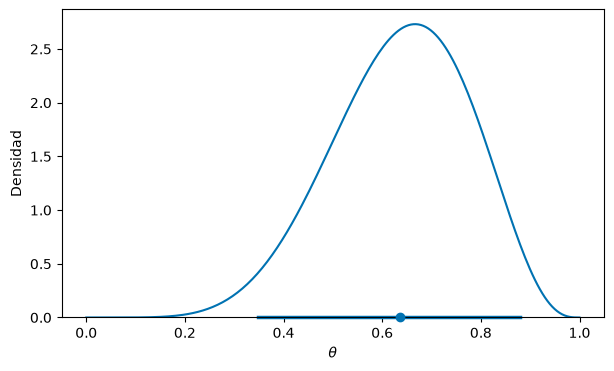

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(theta_grid, theta_posterior.pdf(theta_grid), color=COLORES[0])
marcar_intervalo(ax, theta_posterior, COLORES[0])
ax.set(xlabel=r"$\theta$", ylabel="Densidad", ylim=(0, None))
resumir(theta_posterior);

### Más datos, mismo mecanismo

¿Podemos mejorar esta respuesta? Parece poco...

Imaginemos que seguimos haciendo girar el globo. Para construir este ejemplo hipotético suponemos una proporción verdadera de agua de $2/3$, pero no usamos ese valor para hacer la inferencia.

Consideremos 12 aguas en 18 ensayos en total y 20 aguas en 30 ensayos en total. Son resultados posibles, no garantizados. Mantenemos la misma proporción observada para ver el efecto de tener más datos. No estamos simulando hasta conseguir esos resultados ni sumando tres muestras independientes.

In [11]:
def graficar_beta_binomial(a_prior, b_prior, y, n, intervalo=False):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")

    a_posterior = a_prior + y
    b_posterior = b_prior + n - y

    theta_grid = np.linspace(0.0001, 0.9999, num=256)

    theta_prior_pdf = pz.Beta(a_prior, b_prior).pdf(theta_grid)
    theta_posterior_pdf = pz.Beta(a_posterior, b_posterior).pdf(theta_grid)
    theta_likelihood = pz.Binomial(n=n, p=theta_grid).pdf(y)

    axes[0].plot(theta_grid, theta_prior_pdf, color=COLORES[0])

    axes[1].plot(theta_grid, theta_likelihood, color=COLORES[1])

    axes[2].plot(theta_grid, theta_posterior_pdf, color=COLORES[2])

    title_prior = f"$p(\\theta) \\equiv$Beta({a_prior}, {b_prior})"
    title_likelihood = f"$p(y \\mid \\theta) = \\binom{{{n}}}{{{y}}}\\theta^{{{y}}}(1 - \\theta)^{{{n - y}}}$"
    title_posterior = f"$p(\\theta \\mid y) \\equiv$Beta({a_posterior}, {b_posterior})"

    axes[0].set(yticks=[], xlabel="$\\theta$", title=title_prior)
    axes[1].set(yticks=[], xlabel="$\\theta$", title=title_likelihood)
    axes[2].set(yticks=[], xlabel="$\\theta$", title=title_posterior)

    if intervalo:
        marcar_intervalo(axes[2], pz.Beta(a_posterior, b_posterior), COLORES[2])
    fig.suptitle(f"{y} éxitos en {n} ensayos")
    return fig, axes

12 aguas en 18 ensayos:
Media: 0.65
IC central del 95%: [0.434, 0.837]


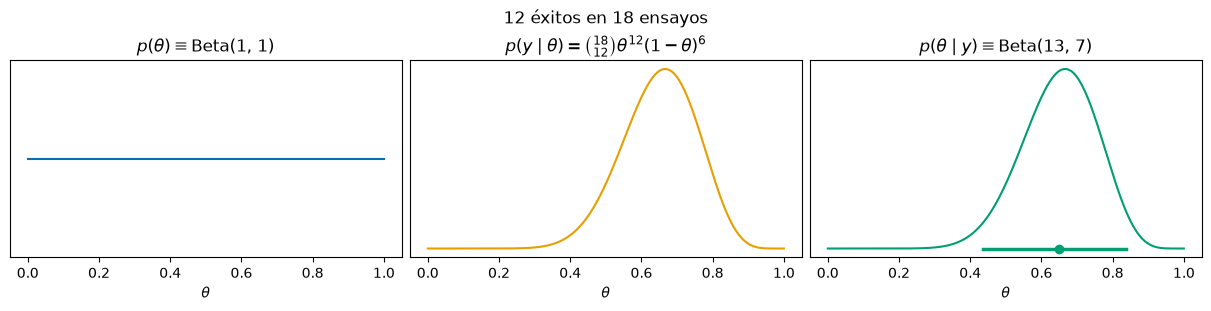

20 aguas en 30 ensayos:
Media: 0.656
IC central del 95%: [0.486, 0.808]


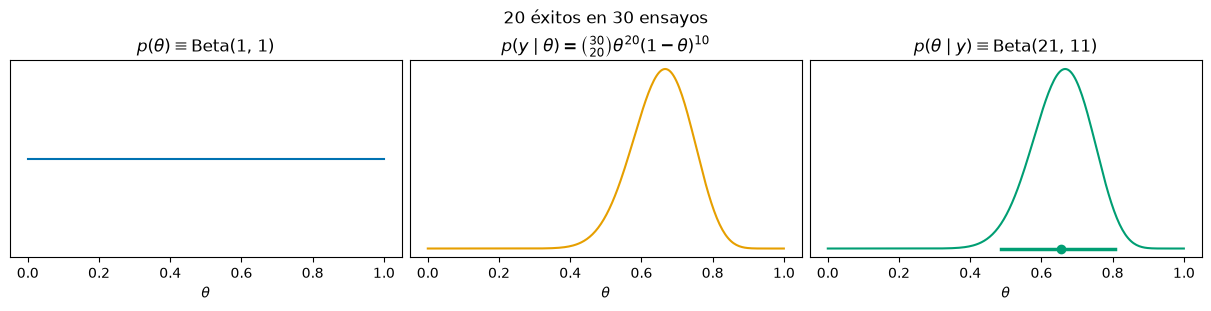

In [12]:
for y, n in [(12, 18), (20, 30)]:
    graficar_beta_binomial(a_prior=1, b_prior=1, y=y, n=n, intervalo=True)
    print(f"{y} aguas en {n} ensayos:")
    resumir(pz.Beta(alpha=1 + y, beta=1 + n - y))
    plt.show()

Con la misma proporción observada, el _posterior_ se concentra y su media se acerca a $2/3$. Un intervalo más estrecho expresa menor incertidumbre bajo el modelo.

¿Y si en lugar de conseguir más datos usamos información previa diferente? Mantengamos los 6 resultados de agua en 9 ensayos, pero usemos un _prior_ $\text{Beta}(10,10)$, más concentrado alrededor de 0.5.

Media: 0.552
IC central del 95%: [0.372, 0.725]


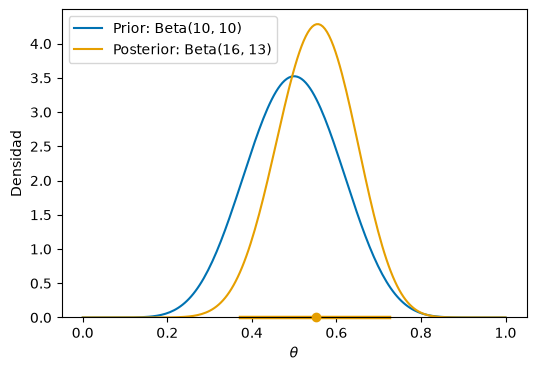

In [13]:
prior_informativo_globo = pz.Beta(alpha=10, beta=10)
posterior_informativo_globo = pz.Beta(alpha=10 + y_globo, beta=10 + n_globo - y_globo)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    theta_grid,
    prior_informativo_globo.pdf(theta_grid),
    color=COLORES[0],
    label="Prior: Beta(10, 10)",
)
ax.plot(
    theta_grid,
    posterior_informativo_globo.pdf(theta_grid),
    color=COLORES[1],
    label="Posterior: Beta(16, 13)",
)
ax.legend()
marcar_intervalo(ax, posterior_informativo_globo, COLORES[1])
ax.set(xlabel=r"$\theta$", ylabel="Densidad", ylim=(0, None))
resumir(posterior_informativo_globo);

### El _posterior_ como compromiso entre el _prior_ y los datos

Podemos interpretar $\alpha$ y $\beta$ como pseudoconteos: al observar los datos sumamos $y$ éxitos y $n-y$ fracasos. No son observaciones reales. Otra convención usa $\alpha-1$ y $\beta-1$, los exponentes de la densidad. Aquí nos interesa la interpretación que surge de la media.

La media _a posteriori_ se puede escribir como un promedio ponderado:

$$
\mathbb{E}(\theta\mid y)=\frac{\alpha+y}{\alpha+\beta+n}
=\underbrace{\frac{\alpha+\beta}{\alpha+\beta+n}}_{\text{peso del prior}}
\frac{\alpha}{\alpha+\beta}
+\underbrace{\frac{n}{\alpha+\beta+n}}_{\text{peso de los datos}}\frac{y}{n}.
$$

Para $n=9$, los _priors_ $\text{Beta}(1,1)$, $\text{Beta}(2,2)$ y $\text{Beta}(10,10)$ pesan aproximadamente 18%, 31% y 69% en esa media. A mayor concentración del _prior_, más datos necesitamos para desplazar la media.

Veamos algunas combinaciones de _priors_ y datos. Estos son ejemplos de la actualización beta-binomial, sin suponer que todos describen el mismo globo.

Uniforme en $\theta$:

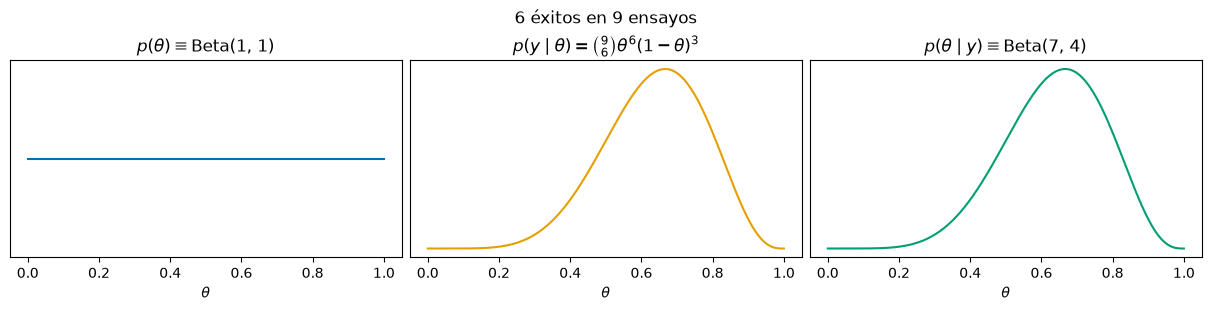

In [14]:
graficar_beta_binomial(a_prior=1, b_prior=1, y=6, n=9);

Levemente informativo (pocos datos):

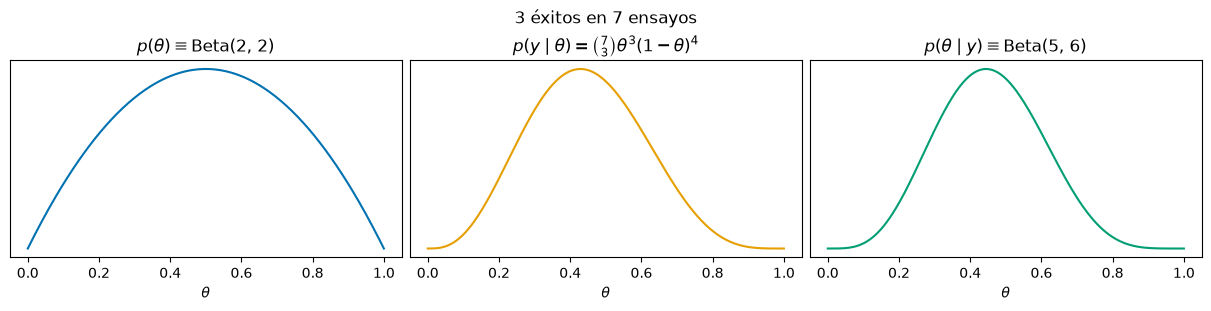

In [15]:
graficar_beta_binomial(a_prior=2, b_prior=2, y=3, n=7);

Levemente informativo (muchos datos):

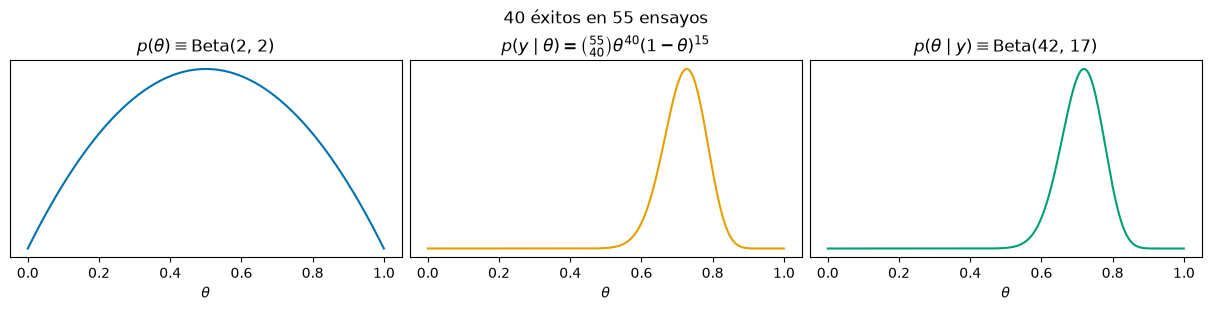

In [16]:
graficar_beta_binomial(a_prior=2, b_prior=2, y=40, n=55);

Informativo (pocos datos):

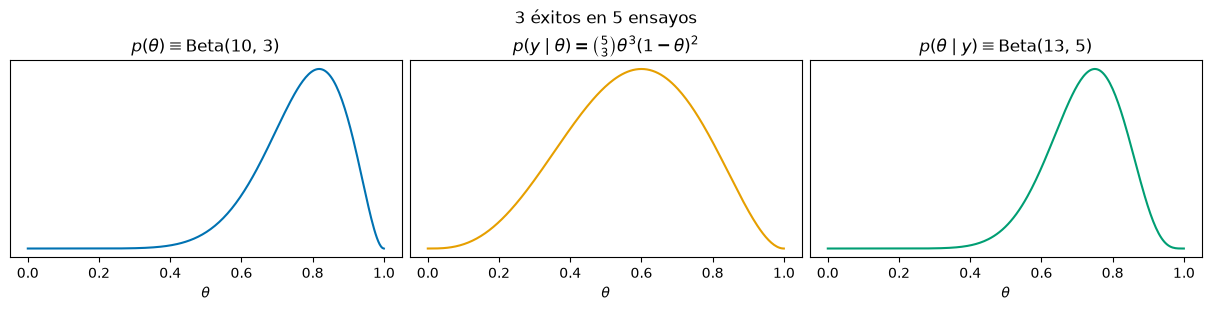

In [17]:
graficar_beta_binomial(a_prior=10, b_prior=3, y=3, n=5);

Informativo (muchos datos):

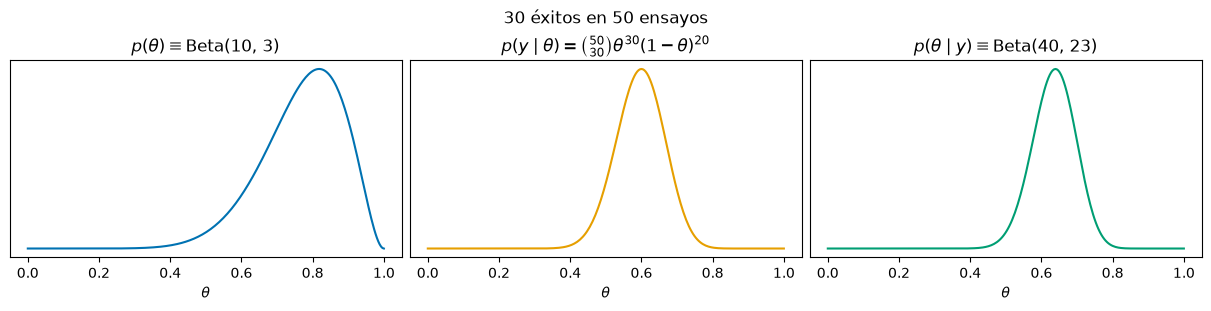

In [18]:
graficar_beta_binomial(a_prior=10, b_prior=3, y=30, n=50);

Cuando el _prior_ es un salvavidas:

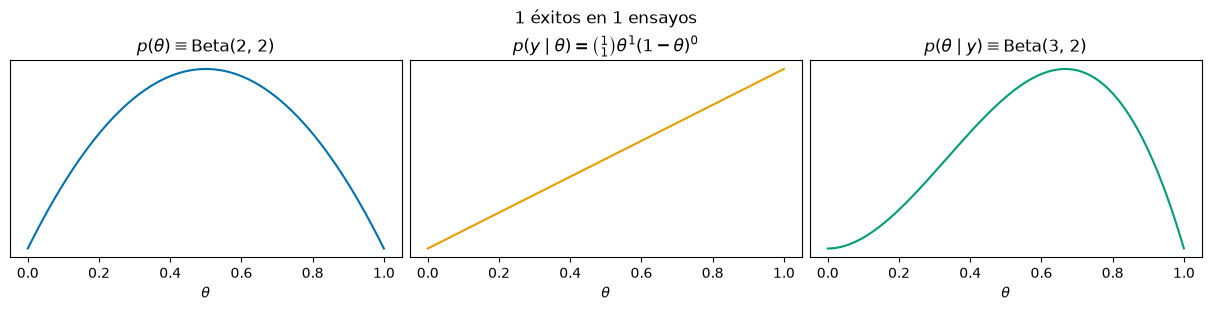

In [19]:
graficar_beta_binomial(a_prior=2, b_prior=2, y=1, n=1);

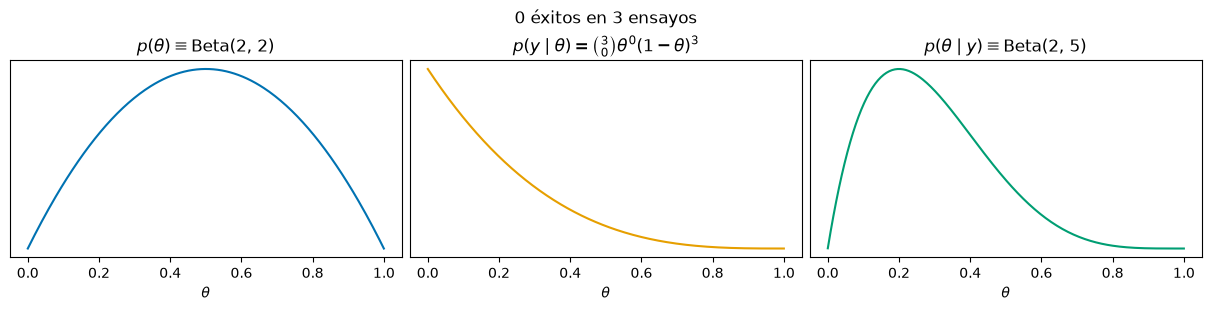

In [20]:
graficar_beta_binomial(a_prior=2, b_prior=2, y=0, n=3);

La forma de actualizar es siempre la misma, pero las respuestas dependen de los supuestos. Un _prior_ concentrado puede ayudar si representa información pertinente, o llevarnos a conclusiones poco adecuadas si no la representa.

Tampoco tener muchos datos corrige un mecanismo de selección que favorezca sistemáticamente ciertas regiones del globo. Vale la pena volver a nuestra dosis de realidad: ¿es adecuado el modelo para la pregunta que queremos responder?